# AH2179 Traffic project — A2: ALL-day models — single model vs regime-split models

**Task:** predict flow (veh/h) at portal 55.620, 15 min ahead, at **every 5-min step of the day**. Results are reported
all day, on the **07:30–08:30 benchmark** window of the assignment, on the afternoon peak, and per traffic regime.

**Question tested here:** does splitting the problem by traffic regime (free flow / congested, from the fundamental-diagram
clustering in A1) and training one model per regime beat a single model that sees the regime only as features?

| Model | Idea |
|---|---|
| persistence, historical average | baselines |
| ridge | linear model on imputed + scaled inputs |
| XGBoost (single) | one model, regime/density/speed are inputs |
| XGBoost regime-split (hard) | two XGBoost models; the regime **at prediction time t** decides which one predicts |
| XGBoost regime-split (soft) | both models, blended with weight P(congested at t) |
| MLP | Keras network on imputed + scaled inputs (`.keras` deliverable) |

The regime of the *target* (t + 15) is unknown when predicting, so routing must use the regime at time t. Transitions
(free → congested onsets, recoveries) are therefore reported separately — they are where a routed model can go wrong.

Splits: train 2021-06-01 – 11-14 (tuning with blocked-by-day CV), val 2021-11-15 – 12-31 (early stopping, model choice),
refit on all 2021, score on the ALL-day `evaluation` file. `final_evaluation` only with `RUN_FINAL = True`, once.

Long steps are **cached** in `../models_allday/cache/` — re-running the notebook reuses them. Set `REFIT = True` to recompute everything.

In [1]:
import warnings, time; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, ParameterSampler
import xgboost as xgb
import traffic_prep as tp

TARGET_P = "p55620"; TARGET = f"q_{TARGET_P}"; Y = f"y_{TARGET}"
RUN_FINAL = True             # set True ONCE, after the model choice is frozen
REFIT = False                # True = ignore cached results and recompute
N_TRIALS = 12                # XGBoost random-search trials (resumable: rerun to continue)
TUNE_BUDGET_S = None         # e.g. 120 to stop tuning after 120 s and continue on the next run
SEED = 42
RES_MIN = 5

IN = Path("../processed_allday"); FIG = Path("../figures_allday"); MOD = Path("../models_allday"); RES = Path("../results_allday")
CACHE = MOD / "cache"
for p in (FIG, MOD, RES, CACHE): p.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

def cached(name, fn):
    f = CACHE / f"{name}.joblib"
    if f.exists() and not REFIT:
        return joblib.load(f)
    t0 = time.time(); obj = fn(); joblib.dump(obj, f)
    print(f"[{name}] computed in {time.time() - t0:.0f} s")
    return obj

D = {n: pd.read_pickle(IN / f"features_{n}.pkl") for n in ["train", "val", "evaluation", "final_evaluation"]}
reg = joblib.load(IN / "regime_model.joblib")
X_COLS = [c for c in D["train"].columns if not c.startswith("y_")]
R_COL = f"r_{TARGET_P}_lag0"
pd.DataFrame({n: {"rows": len(d), "target missing": int(d[Y].isna().sum()),
                  "congested at t (routing)": int((d[R_COL] >= .5).sum()),
                  "congested at t+15 (truth)": int((d[f"y_reg_{TARGET}"] == 1).sum())} for n, d in D.items()})

,train,val,evaluation,final_evaluation
rows,48093,13537,23040,29088
target missing,2692,119,1216,2181
congested at t (routing),5153,1441,2250,2569
congested at t+15 (truth),4981,1426,2177,2487


## 1. Evaluation helpers, subsets and baselines

In [2]:
def subsets(d):
    '''Boolean masks of the evaluation subsets (rows with a valid target only).'''
    ok = d[Y].notna(); tod = d["tod_target_min"]; rt = d[R_COL]; ry = d[f"y_reg_{TARGET}"]
    return {"all day": ok,
            "07:30–08:30 (benchmark)": ok & tod.between(450, 510),
            "15:00–18:00 (afternoon peak)": ok & tod.between(900, 1080),
            "free flow at t+15": ok & (ry == 0),
            "congested at t+15": ok & (ry == 1),
            "onset: free at t → congested at t+15": ok & (rt < .5) & (ry == 1),
            "recovery: congested at t → free at t+15": ok & (rt >= .5) & (ry == 0)}

def rmse(y, p): return float(np.sqrt(((p - y) ** 2).mean()))
def mae(y, p): return float((p - y).abs().mean())

def report(preds, split, metric=rmse):
    d = D[split]; y = d[Y]; S = subsets(d)
    out = {name: {k: metric(y[m], p[m]) for k, p in preds.items()} for name, m in S.items()}
    t = pd.DataFrame(out).T
    t.insert(0, "n", [int(m.sum()) for m in S.values()])
    return t.round(0)

def day_block_cv(index, n_splits=3):
    '''Expanding-window CV over whole days (a day = bins ending 00:05 … 24:00).'''
    day = (index - pd.Timedelta(minutes=RES_MIN)).normalize()
    days = np.array(sorted(day.unique()))
    for a, b in TimeSeriesSplit(n_splits).split(days):
        yield np.where(day.isin(days[a]))[0], np.where(day.isin(days[b]))[0]

def baselines(d):
    hist = d[f"hist_{TARGET}"]
    return {"persistence": d[f"{TARGET}_lag0"].fillna(hist), "historical average": hist}

pred = {s: baselines(D[s]) for s in D}
tr = D["train"][D["train"][Y].notna()]; va = D["val"][D["val"][Y].notna()]
report(pred["val"], "val")

,n,persistence,historical average
all day,13418,382.0,452.0
07:30–08:30 (benchmark),611,355.0,541.0
15:00–18:00 (afternoon peak),1738,558.0,660.0
free flow at t+15,11992,347.0,440.0
congested at t+15,1426,604.0,542.0
onset: free at t → congested at t+15,156,716.0,626.0
recovery: congested at t → free at t+15,168,1077.0,622.0


## 2. Ridge regression
Inputs: `tp.FeatureImputer` (causal, fitted on train) + missing flags → z-score (train statistics). Alpha by blocked CV.

In [3]:
imp = tp.FeatureImputer().fit(tr[X_COLS])
DENSE_COLS = list(imp.transform(tr[X_COLS].head(5)).columns)
sc = StandardScaler().fit(imp.transform(tr[X_COLS])[DENSE_COLS])
Z = lambda d, imp=imp, sc=sc: sc.transform(imp.transform(d[X_COLS])[DENSE_COLS])

ridge = cached("ridge_train", lambda: RidgeCV(alphas=np.logspace(-2, 4, 25), cv=list(day_block_cv(tr.index)),
                                              scoring="neg_root_mean_squared_error").fit(Z(tr), tr[Y]))
print("alpha:", ridge.alpha_)
for s in D: pred[s]["ridge"] = pd.Series(ridge.predict(Z(D[s])), index=D[s].index)
report(pred["val"], "val")

alpha: 0.5623413251903491


,n,persistence,historical average,ridge
all day,13418,382.0,452.0,312.0
07:30–08:30 (benchmark),611,355.0,541.0,337.0
15:00–18:00 (afternoon peak),1738,558.0,660.0,481.0
free flow at t+15,11992,347.0,440.0,280.0
congested at t+15,1426,604.0,542.0,508.0
onset: free at t → congested at t+15,156,716.0,626.0,606.0
recovery: congested at t → free at t+15,168,1077.0,622.0,686.0


## 3. XGBoost — single model
Random search scored by blocked time-series CV on the train split (resumable: trials are appended to a CSV, so
re-running continues where it stopped). The tree count is then fixed by early stopping on the validation split.

In [4]:
space = {"max_depth": [4, 5, 6, 8], "min_child_weight": [1, 5, 10, 20], "subsample": [0.6, 0.8, 1.0],
         "colsample_bytree": [0.3, 0.5, 0.7], "reg_lambda": [1, 5, 10, 30], "gamma": [0, 1, 5]}
base = dict(n_estimators=4000, learning_rate=0.05, tree_method="hist", max_bin=128, objective="reg:squarederror",
            early_stopping_rounds=50, n_jobs=4, random_state=SEED, eval_metric="rmse")
TRIALS = RES / f"xgb_trials_{TARGET}.csv"

def run_tuning():
    done = pd.read_csv(TRIALS) if TRIALS.exists() and not REFIT else pd.DataFrame()
    folds = list(day_block_cv(tr.index, 3)); t0 = time.time()
    for i, params in enumerate(ParameterSampler(space, N_TRIALS, random_state=SEED)):
        if i < len(done): continue
        if TUNE_BUDGET_S and time.time() - t0 > TUNE_BUDGET_S:
            print(f"time budget reached after {len(done)} trials — re-run this cell to continue"); break
        sc_, it = [], []
        for a, b in folds:
            m = xgb.XGBRegressor(**base, **params)
            m.fit(tr[X_COLS].iloc[a], tr[Y].iloc[a], eval_set=[(tr[X_COLS].iloc[b], tr[Y].iloc[b])], verbose=False)
            sc_.append(m.best_score); it.append(m.best_iteration)
        done = pd.concat([done, pd.DataFrame([{"trial": i, **params, "cv_rmse": np.mean(sc_), "cv_sd": np.std(sc_),
                                               "iters": int(np.mean(it))}])], ignore_index=True)
        done.to_csv(TRIALS, index=False)
    return done

trials = run_tuning().sort_values("cv_rmse")
BEST = {k: (int(v) if k in ("max_depth", "min_child_weight") else float(v)) for k, v in trials.iloc[0][list(space)].items()}
print(f"{len(trials)} trials, best:", BEST)
trials.head(5).round(1)

12 trials, best: {'max_depth': 8, 'min_child_weight': 10, 'subsample': 1.0, 'colsample_bytree': 0.5, 'reg_lambda': 1.0, 'gamma': 5.0}


,trial,subsample,reg_lambda,min_child_weight,max_depth,gamma,colsample_bytree,cv_rmse,cv_sd,iters
4,4,1.0,1,10,8,5,0.5,303.7,12.4,146
1,1,0.8,10,5,6,1,0.7,303.8,11.9,195
11,11,1.0,1,20,5,0,0.7,304.2,9.6,203
5,5,0.6,5,20,6,5,0.5,304.6,11.5,192
9,9,0.8,1,10,6,0,0.3,304.8,10.9,198


In [5]:
def fit_es(Xtr, ytr, Xva, yva, params=None):
    m = xgb.XGBRegressor(**base, **(params or BEST))
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m

xgb_single = cached("xgb_single_train", lambda: fit_es(tr[X_COLS], tr[Y], va[X_COLS], va[Y]))
N_TREES = xgb_single.best_iteration + 1
print("trees:", N_TREES)
for s in D: pred[s]["xgb single"] = pd.Series(xgb_single.predict(D[s][X_COLS], iteration_range=(0, N_TREES)), index=D[s].index)
report(pred["val"], "val")

trees: 287


,n,persistence,historical average,ridge,xgb single
all day,13418,382.0,452.0,312.0,284.0
07:30–08:30 (benchmark),611,355.0,541.0,337.0,272.0
15:00–18:00 (afternoon peak),1738,558.0,660.0,481.0,458.0
free flow at t+15,11992,347.0,440.0,280.0,243.0
congested at t+15,1426,604.0,542.0,508.0,512.0
onset: free at t → congested at t+15,156,716.0,626.0,606.0,597.0
recovery: congested at t → free at t+15,168,1077.0,622.0,686.0,617.0


## 4. XGBoost — regime-split models
Training rows are split by the regime **at time t** at the target portal (`r_p55620_lag0 ≥ 0.5` → congested model).
If the target's own speed is missing, the routing falls back to the mean regime probability of the other portals — in A1 the whole
corridor was congested almost simultaneously, so neighbours are a good proxy. Both regime models use the tuned hyper-parameters;
each gets its own tree count by early stopping on the validation rows of its regime.

In [6]:
r_cols = [f"r_{tp.PORTAL_COL[k]}_lag0" for k in tp.PORTALS_DOWNSTREAM]
def route_p(d):
    '''P(congested at t) used for routing: target portal, else mean of the other portals, else 0.'''
    p = d[R_COL].copy()
    return p.fillna(d[[c for c in r_cols if c != R_COL]].mean(axis=1)).fillna(0.0)

def fit_split(trn, val):
    rt, rv = route_p(trn) >= .5, route_p(val) >= .5
    return {"free": fit_es(trn[X_COLS][~rt], trn[Y][~rt], val[X_COLS][~rv], val[Y][~rv]),
            "cong": fit_es(trn[X_COLS][rt], trn[Y][rt], val[X_COLS][rv], val[Y][rv])}

split = cached("xgb_split_train", lambda: fit_split(tr, va))
N_SPLIT = {k: m.best_iteration + 1 for k, m in split.items()}
print("rows free / congested (train):", int((route_p(tr) < .5).sum()), "/", int((route_p(tr) >= .5).sum()), "| trees:", N_SPLIT)

def predict_split(models, d, n_trees, soft=False):
    pf = models["free"].predict(d[X_COLS], iteration_range=(0, n_trees["free"]))
    pc = models["cong"].predict(d[X_COLS], iteration_range=(0, n_trees["cong"]))
    w = route_p(d).to_numpy()
    return pd.Series(w * pc + (1 - w) * pf if soft else np.where(w >= .5, pc, pf), index=d.index)

for s in D:
    pred[s]["xgb split (hard)"] = predict_split(split, D[s], N_SPLIT)
    pred[s]["xgb split (soft)"] = predict_split(split, D[s], N_SPLIT, soft=True)
report(pred["val"], "val")

rows free / congested (train): 40418 / 4983 | trees: {'free': 227, 'cong': 45}


,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft)
all day,13418,382.0,452.0,312.0,284.0,285.0,284.0
07:30–08:30 (benchmark),611,355.0,541.0,337.0,272.0,287.0,287.0
15:00–18:00 (afternoon peak),1738,558.0,660.0,481.0,458.0,452.0,451.0
free flow at t+15,11992,347.0,440.0,280.0,243.0,247.0,246.0
congested at t+15,1426,604.0,542.0,508.0,512.0,501.0,500.0
onset: free at t → congested at t+15,156,716.0,626.0,606.0,597.0,593.0,590.0
recovery: congested at t → free at t+15,168,1077.0,622.0,686.0,617.0,645.0,644.0


## 5. Keras MLP

In [7]:
import tensorflow as tf
from tensorflow import keras
YS = 1000.0

def make_mlp(n_in):
    m = keras.Sequential([keras.Input((n_in,)),
                          keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(0.2),
                          keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.2),
                          keras.layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m

def train_mlp():
    keras.utils.set_random_seed(SEED)
    m = make_mlp(len(DENSE_COLS))
    h = m.fit(Z(tr), tr[Y] / YS, validation_data=(Z(va), va[Y] / YS), epochs=100, batch_size=256, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)])
    m.save(MOD / f"mlp_train_{TARGET}.keras")
    return {"best_epoch": int(np.argmin(h.history["val_loss"])) + 1, "hist": h.history,
            "pred": {s: m.predict(Z(D[s]), verbose=0, batch_size=2048).ravel() * YS for s in D}}

mlp_res = cached("mlp_train", train_mlp)
for s in D: pred[s]["mlp"] = pd.Series(mlp_res["pred"][s], index=D[s].index)
print("best epoch:", mlp_res["best_epoch"])
res_val = report(pred["val"], "val"); res_val.to_csv(RES / f"val_rmse_{TARGET}.csv"); res_val

best epoch: 13


,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft),mlp
all day,13418,382.0,452.0,312.0,284.0,285.0,284.0,299.0
07:30–08:30 (benchmark),611,355.0,541.0,337.0,272.0,287.0,287.0,309.0
15:00–18:00 (afternoon peak),1738,558.0,660.0,481.0,458.0,452.0,451.0,467.0
free flow at t+15,11992,347.0,440.0,280.0,243.0,247.0,246.0,259.0
congested at t+15,1426,604.0,542.0,508.0,512.0,501.0,500.0,526.0
onset: free at t → congested at t+15,156,716.0,626.0,606.0,597.0,593.0,590.0,596.0
recovery: congested at t → free at t+15,168,1077.0,622.0,686.0,617.0,645.0,644.0,644.0


## 6. Refit on all 2021 data → ALL-day evaluation file
Hyper-parameters, tree counts and epochs are frozen from above (×1.15 for the ~28 % larger training set).

In [8]:
full = pd.read_pickle(IN / "features_full.pkl"); full = full[full[Y].notna()]     # all 2021, out-of-fold hist input (A1)
imp_f = tp.FeatureImputer().fit(full[X_COLS])
sc_f = StandardScaler().fit(imp_f.transform(full[X_COLS])[DENSE_COLS])
Zf = lambda d: sc_f.transform(imp_f.transform(d[X_COLS])[DENSE_COLS])

def fit_fixed(Xd, yd, n):
    m = xgb.XGBRegressor(**{**base, "early_stopping_rounds": None, "n_estimators": int(n * 1.15)}, **BEST)
    return m.fit(Xd, yd, verbose=False)

def refit_all():
    rf = route_p(full) >= .5
    return {"ridge": RidgeCV(alphas=[ridge.alpha_]).fit(Zf(full), full[Y]),
            "xgb single": fit_fixed(full[X_COLS], full[Y], N_TREES),
            "split": {"free": fit_fixed(full[X_COLS][~rf], full[Y][~rf], N_SPLIT["free"]),
                      "cong": fit_fixed(full[X_COLS][rf], full[Y][rf], N_SPLIT["cong"])}}
F = cached("refit_2021", refit_all)
N_BIG = {k: int(v * 1.15) for k, v in N_SPLIT.items()}

def train_mlp_full():
    keras.utils.set_random_seed(SEED)
    m = make_mlp(len(DENSE_COLS))
    m.fit(Zf(full), full[Y] / YS, epochs=int(mlp_res["best_epoch"] * 1.15), batch_size=256, verbose=0)
    m.save(MOD / f"mlp_{TARGET}.keras")                       # <- .keras deliverable
    return {s: m.predict(Zf(D[s]), verbose=0, batch_size=2048).ravel() * YS for s in ["evaluation", "final_evaluation"]}
mlp_full = cached("mlp_refit_2021", train_mlp_full)

final_models = {"ridge": lambda d: F["ridge"].predict(Zf(d)),
                "xgb single": lambda d: F["xgb single"].predict(d[X_COLS]),
                "xgb split (hard)": lambda d: predict_split(F["split"], d, N_BIG).to_numpy(),
                "xgb split (soft)": lambda d: predict_split(F["split"], d, N_BIG, soft=True).to_numpy()}
for s in ["evaluation", "final_evaluation"]:
    for k, f in final_models.items(): pred[s][k] = pd.Series(f(D[s]), index=D[s].index)
    pred[s]["mlp"] = pd.Series(mlp_full[s], index=D[s].index)

res_eval = report(pred["evaluation"], "evaluation"); res_eval.to_csv(RES / f"evaluation_rmse_{TARGET}.csv")
res_eval

,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft),mlp
all day,21824,403.0,462.0,326.0,306.0,305.0,305.0,337.0
07:30–08:30 (benchmark),1040,411.0,378.0,304.0,285.0,274.0,275.0,322.0
15:00–18:00 (afternoon peak),2958,559.0,665.0,487.0,464.0,467.0,467.0,494.0
free flow at t+15,19646,370.0,436.0,292.0,265.0,262.0,262.0,304.0
congested at t+15,2177,623.0,651.0,543.0,554.0,557.0,557.0,548.0
onset: free at t → congested at t+15,297,749.0,702.0,653.0,672.0,685.0,684.0,665.0
recovery: congested at t → free at t+15,289,1045.0,651.0,664.0,595.0,572.0,570.0,676.0


In [9]:
report(pred["evaluation"], "evaluation", metric=mae)      # same table, MAE (veh/h)

,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft),mlp
all day,21824,274.0,324.0,226.0,206.0,206.0,206.0,240.0
07:30–08:30 (benchmark),1040,291.0,304.0,222.0,201.0,198.0,198.0,236.0
15:00–18:00 (afternoon peak),2958,384.0,499.0,353.0,335.0,337.0,337.0,354.0
free flow at t+15,19646,259.0,304.0,208.0,185.0,184.0,184.0,224.0
congested at t+15,2177,412.0,500.0,387.0,396.0,406.0,407.0,386.0
onset: free at t → congested at t+15,297,519.0,543.0,459.0,470.0,477.0,476.0,484.0
recovery: congested at t → free at t+15,289,863.0,492.0,517.0,422.0,421.0,418.0,489.0


In [10]:
# Is the split-vs-single difference real? Day-block bootstrap of the RMSE difference (evaluation file).
def boot_diff(a, b, mask, n=1000, seed=SEED):
    d_ = D["evaluation"]; m = mask & d_[Y].notna()
    day = (d_.index[m] - pd.Timedelta(minutes=5)).normalize()
    e = pd.DataFrame({"a": (pred["evaluation"][a][m] - d_[Y][m]) ** 2, "b": (pred["evaluation"][b][m] - d_[Y][m]) ** 2, "day": day})
    g = e.groupby("day")[["a", "b"]].agg(["sum", "count"])
    sa, sb, cnt = g[("a", "sum")].to_numpy(), g[("b", "sum")].to_numpy(), g[("a", "count")].to_numpy()
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = rng.integers(0, len(g), len(g))
        out.append(np.sqrt(sb[i].sum() / cnt[i].sum()) - np.sqrt(sa[i].sum() / cnt[i].sum()))
    return np.sqrt(sb.sum() / cnt.sum()) - np.sqrt(sa.sum() / cnt.sum()), *np.percentile(out, [2.5, 97.5])

S_eval = subsets(D["evaluation"])
rows = {}
for name in ["all day", "07:30–08:30 (benchmark)", "congested at t+15", "onset: free at t → congested at t+15"]:
    for b in ["xgb split (hard)", "xgb split (soft)"]:
        dlt, lo, hi = boot_diff("xgb single", b, S_eval[name])
        rows[(name, b)] = {"RMSE(split) − RMSE(single)": round(dlt, 1), "95 % CI low": round(lo, 1), "95 % CI high": round(hi, 1)}
pd.DataFrame(rows).T

RMSE(split) − RMSE(single)  \
all day                              xgb split (hard)                        -1.6   
                                     xgb split (soft)                        -1.7   
07:30–08:30 (benchmark)              xgb split (hard)                       -10.5   
                                     xgb split (soft)                       -10.1   
congested at t+15                    xgb split (hard)                         2.3   
                                     xgb split (soft)                         2.6   
onset: free at t → congested at t+15 xgb split (hard)                        13.4   
                                     xgb split (soft)                        12.5   

                                                       95 % CI low  \
all day                              xgb split (hard)         -4.3   
                                     xgb split (soft)         -4.6   
07:30–08:30 (benchmark)              xgb split (hard)        -23.4   
                                     xgb split (soft)        -22.7   
congested at t+15                    xgb split (hard)        -10.1   
                                     xgb split (soft)         -9.6   
onset: free at t → congested at t+15 xgb split (hard)         -9.2   
                                     xgb split (soft)         -9.7   

                                                       95 % CI high  
all day                              xgb split (hard)           1.2  
                                     xgb split (soft)           1.1  
07:30–08:30 (benchmark)              xgb split (hard)           1.8  
                                     xgb split (soft)           1.8  
congested at t+15                    xgb split (hard)          15.2  
                                     xgb split (soft)          15.4  
onset: free at t → congested at t+15 xgb split (hard)          31.4  
                                     xgb split (soft)          29.0

## 7. Diagnostics (evaluation file)

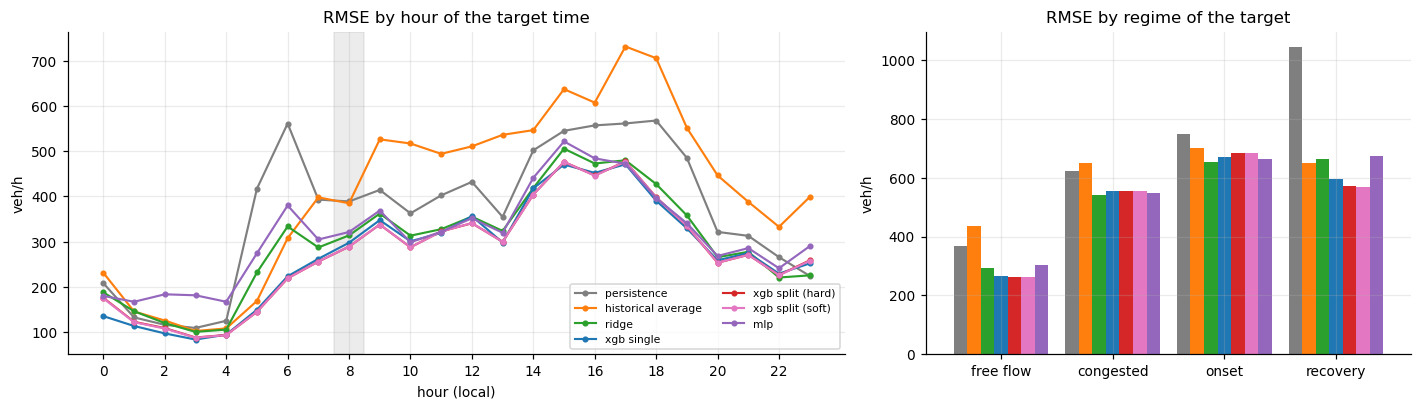

In [11]:
S = "evaluation"; d = D[S]; y = d[Y]; ok = y.notna()
MODELS = ["persistence", "historical average", "ridge", "xgb single", "xgb split (hard)", "xgb split (soft)", "mlp"]
COL = dict(zip(MODELS, ["C7", "C1", "C2", "C0", "C3", "C6", "C4"]))
hour = (d["tod_target_min"] // 60)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for k in MODELS:
    e = (pred[S][k] - y)[ok]
    ax[0].plot(e.groupby(hour[ok]).apply(lambda s: np.sqrt((s ** 2).mean())), "o-", ms=3, lw=1.4, color=COL[k], label=k)
ax[0].axvspan(7.5, 8.5, color="grey", alpha=.15); ax[0].set_xticks(range(0, 24, 2))
ax[0].set(title="RMSE by hour of the target time", xlabel="hour (local)", ylabel="veh/h"); ax[0].legend(fontsize=7, ncol=2)
sub = res_eval.drop(columns="n").loc[["free flow at t+15", "congested at t+15", "onset: free at t → congested at t+15",
                                      "recovery: congested at t → free at t+15"], MODELS]
sub.index = ["free flow", "congested", "onset", "recovery"]
sub.plot.bar(ax=ax[1], rot=0, color=[COL[k] for k in MODELS], width=.85, legend=False)
ax[1].set(title="RMSE by regime of the target", ylabel="veh/h")
fig.tight_layout(); save(fig, "A2_error_by_hour_and_regime"); plt.show()

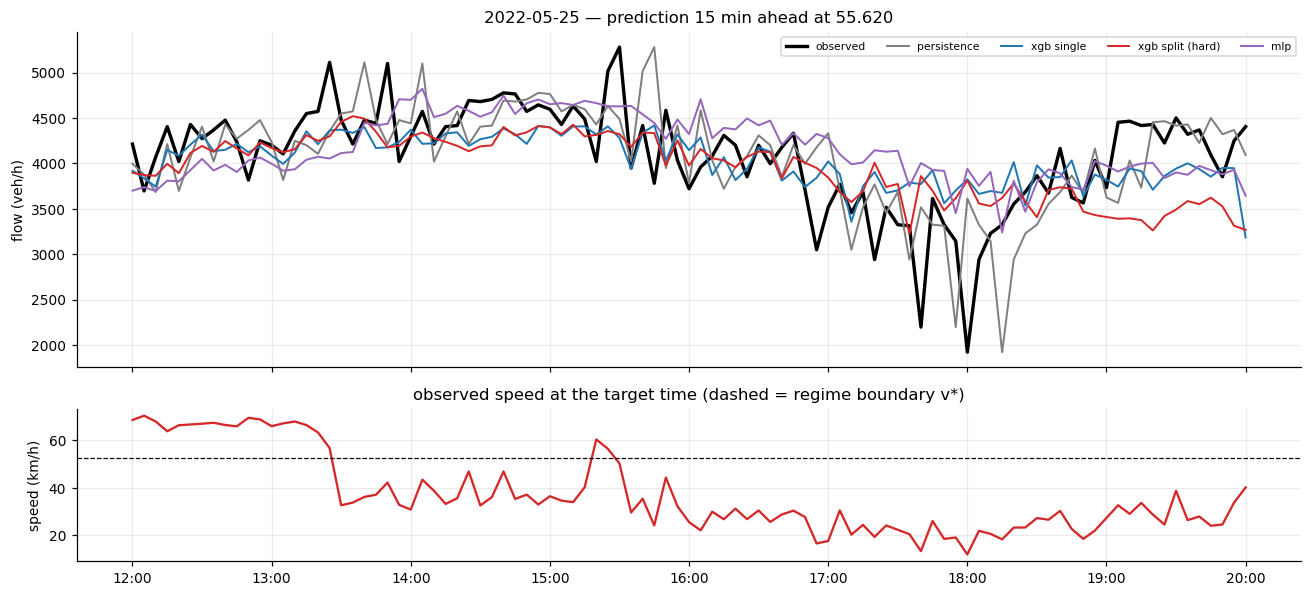

In [12]:
# the most congested evaluation afternoon: observed vs predictions
pm = d[d.tod_target_min.between(780, 1200)]
day = pm.groupby((pm.index - pd.Timedelta(minutes=5)).normalize())[f"v_{TARGET_P}_lag0"].mean().idxmin()
dd = (d.index - pd.Timedelta(minutes=5)).normalize() == day
w = d[dd & d.tod_target_min.between(720, 1200)]
tt = w.index + pd.Timedelta(minutes=15)
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax[0].plot(tt, w[Y], "k-", lw=2.2, label="observed")
for k in ["persistence", "xgb single", "xgb split (hard)", "mlp"]:
    ax[0].plot(tt, pred[S][k][w.index], lw=1.3, color=COL[k], label=k)
ax[0].set(ylabel="flow (veh/h)", title=f"{day.date()} — prediction 15 min ahead at 55.620"); ax[0].legend(fontsize=7, ncol=5)
ax[1].plot(tt, w[f"y_v_{TARGET_P}"], color="C3", lw=1.5); ax[1].axhline(reg.vstar[TARGET_P], color="k", ls="--", lw=.8)
ax[1].set(ylabel="speed (km/h)", title="observed speed at the target time (dashed = regime boundary v*)")
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
fig.tight_layout(); save(fig, "A2_example_afternoon"); plt.show()

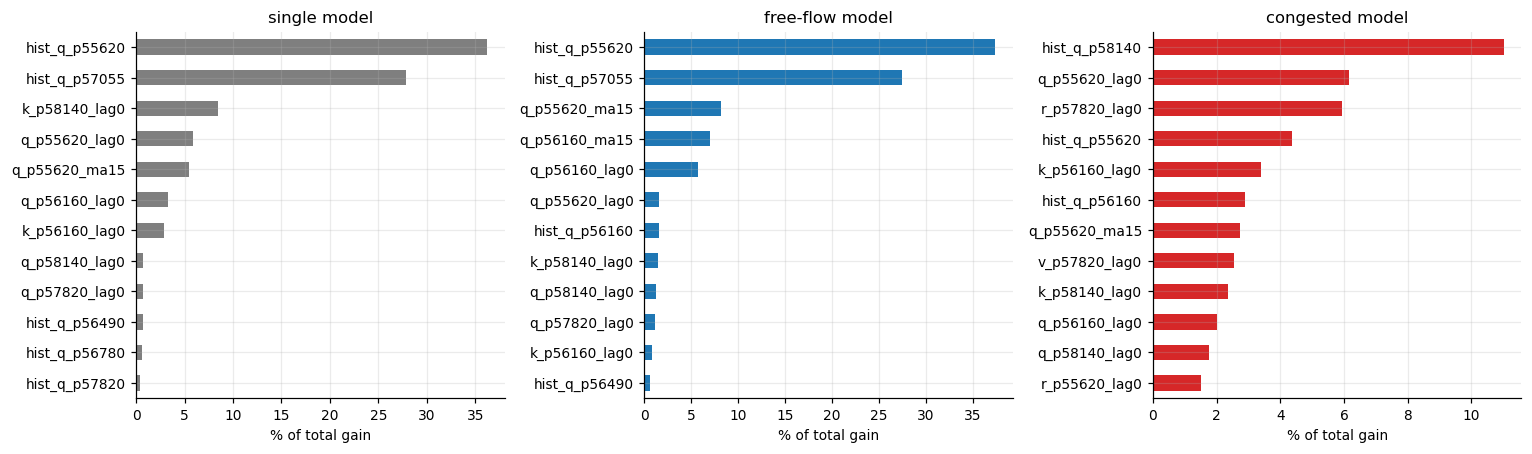

In [13]:
# what drives each regime model? (share of total gain, top 12)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, (name, m) in zip(ax, [("single model", F["xgb single"]), ("free-flow model", F["split"]["free"]),
                             ("congested model", F["split"]["cong"])]):
    g = pd.Series(m.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
    (g.head(12)[::-1] / g.sum() * 100).plot.barh(ax=a, color="C0" if "free" in name else ("C3" if "cong" in name else "C7"))
    a.set(title=name, xlabel="% of total gain")
fig.tight_layout(); save(fig, "A2_feature_importance_by_regime"); plt.show()

## 8. Robustness to sensor failures, with masking augmentation
As in notebook 02: inputs of the evaluation file are blanked (whole target portal, all other portals, random 20 %), and the
models are retrained with 2 extra masked copies of every training row (`tp.mask_augment`). Tree counts are reused.

In [14]:
pf = tp.portal_feature_map(X_COLS)
own = pf[TARGET_P]; others = sorted({c for p, cs in pf.items() if p != TARGET_P for c in cs} - set(own))
value_cols = sorted({c for cs in pf.values() for c in cs})
def mask_random(df, frac=0.2, seed=SEED):
    df = df.copy(); M = np.random.default_rng(seed).random((len(df), len(value_cols))) < frac
    df[value_cols] = df[value_cols].mask(M); return df
SCEN = {"no failure": lambda df: df,
        "target portal down": lambda df: df.assign(**{c: np.nan for c in own}),
        "all other portals down": lambda df: df.assign(**{c: np.nan for c in others}),
        "random 20 % missing": mask_random}

def refit_aug():
    fa = tp.mask_augment(full, X_COLS, n_copies=2, seed=1)
    ra = route_p(fa) >= .5
    return {"xgb single + aug": fit_fixed(fa[X_COLS], fa[Y], N_TREES),
            "split": {"free": fit_fixed(fa[X_COLS][~ra], fa[Y][~ra], N_SPLIT["free"]),
                      "cong": fit_fixed(fa[X_COLS][ra], fa[Y][ra], N_SPLIT["cong"])},
            "ridge + aug": RidgeCV(alphas=[ridge.alpha_]).fit(Zf(fa), fa[Y])}
A = cached("refit_2021_aug", refit_aug)
aug_models = {"ridge + aug": lambda d: A["ridge + aug"].predict(Zf(d)),
              "xgb single + aug": lambda d: A["xgb single + aug"].predict(d[X_COLS]),
              "xgb split (soft) + aug": lambda d: predict_split(A["split"], d, N_BIG, soft=True).to_numpy()}
rob_models = {k: final_models[k] for k in ["ridge", "xgb single", "xgb split (soft)"]} | aug_models
rob = pd.DataFrame({sc: {k: rmse(y[ok], pd.Series(f(fn(d)), index=d.index)[ok]) for k, f in rob_models.items()}
                    for sc, fn in SCEN.items()}).T
rob["historical average"] = rmse(y[ok], pred[S]["historical average"][ok])
rob.to_csv(RES / f"robustness_{TARGET}.csv"); rob.round(0)

,ridge,xgb single,xgb split (soft),ridge + aug,xgb single + aug,xgb split (soft) + aug,historical average
no failure,326.0,306.0,305.0,354.0,300.0,299.0,462.0
target portal down,373.0,420.0,391.0,358.0,307.0,304.0,462.0
all other portals down,360.0,421.0,439.0,367.0,347.0,347.0,462.0
random 20 % missing,343.0,356.0,348.0,355.0,304.0,303.0,462.0


In [15]:
for s in ["evaluation", "final_evaluation"]:
    for k, f in aug_models.items(): pred[s][k] = pd.Series(f(D[s]), index=D[s].index)
res_all = report(pred["evaluation"], "evaluation"); res_all.to_csv(RES / f"evaluation_rmse_all_{TARGET}.csv")
# save the refitted models
F["xgb single"].save_model(MOD / f"xgb_single_{TARGET}.json")
A["xgb single + aug"].save_model(MOD / f"xgb_single_aug_{TARGET}.json")
for r_ in ["free", "cong"]:
    F["split"][r_].save_model(MOD / f"xgb_split_{r_}_{TARGET}.json")
    A["split"][r_].save_model(MOD / f"xgb_split_{r_}_aug_{TARGET}.json")
joblib.dump({"imputer": imp_f, "scaler": sc_f, "dense_cols": DENSE_COLS, "x_cols": X_COLS, "ridge": F["ridge"],
             "ridge_aug": A["ridge + aug"], "xgb_params": BEST, "trees_single": int(N_TREES * 1.15), "trees_split": N_BIG,
             "routing": "P(congested at t) at target portal, fallback mean of other portals; hard >= 0.5 / soft blend",
             "regime_vstar": reg.vstar}, MOD / f"prep_{TARGET}.joblib")
res_all

,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft),mlp,ridge + aug,xgb single + aug,xgb split (soft) + aug
all day,21824,403.0,462.0,326.0,306.0,305.0,305.0,337.0,354.0,300.0,299.0
07:30–08:30 (benchmark),1040,411.0,378.0,304.0,285.0,274.0,275.0,322.0,314.0,268.0,277.0
15:00–18:00 (afternoon peak),2958,559.0,665.0,487.0,464.0,467.0,467.0,494.0,524.0,464.0,457.0
free flow at t+15,19646,370.0,436.0,292.0,265.0,262.0,262.0,304.0,325.0,259.0,259.0
congested at t+15,2177,623.0,651.0,543.0,554.0,557.0,557.0,548.0,552.0,544.0,539.0
onset: free at t → congested at t+15,297,749.0,702.0,653.0,672.0,685.0,684.0,665.0,658.0,663.0,661.0
recovery: congested at t → free at t+15,289,1045.0,651.0,664.0,595.0,572.0,570.0,676.0,632.0,552.0,586.0


## Conclusions (target 55.620, ALL-day `evaluation` file, RMSE veh/h — leakage-safe pipeline, see A1 section 4)

| | persistence | hist. avg | ridge | XGB single | XGB split (hard/soft) | MLP | **XGB + aug** (selected) |
|---|---|---|---|---|---|---|---|
| all day | 403 | 462 | 326 | 306 | 305 / 305 | 337 | **300** |
| 07:30–08:30 benchmark | 411 | 378 | 304 | 285 | 274 / 275 | 322 | **268** |
| congested at t+15 | 623 | 651 | 543 | 554 | 557 / 557 | 548 | **544** |
| onset (free → congested) | 749 | 702 | 653 | 672 | 685 / 684 | 665 | **663** |

1. **Regime-split models do not beat the single model.** With the regime (and speed, density, neighbours' regimes) available as
   inputs, one XGBoost model already learns the regime-specific behaviour through its splits. The day-block bootstrap puts the
   split-minus-single differences at −2 veh/h all day, −10 on the 07:30–08:30 window, +2.5 in congestion and +13 at onsets —
   every 95 % interval contains zero, including in congestion and at onsets, where a split model was expected to help most.
   The single model is simpler and is kept.
2. **Congestion is where the error is** (≈ 550 vs ≈ 260 veh/h in free flow), for every model. In the congested regime the flow at
   55.620 is set by the discharge of a bottleneck *downstream of the study area* and oscillates in stop-and-go waves (see the example
   afternoon); the congested model spreads its importance thinly over many weak features — there is little predictable signal
   15 min ahead in these 8 portals. Onsets are the hardest case: the regime at t says "free", so no routing can anticipate them.
3. **Using all day improves the data, not only the scope:** the models are trained on ≈ 59 k rows instead of ≈ 2.8 k, and XGBoost
   reaches 268–285 veh/h on the benchmark window of this split. (Not directly comparable with notebook 02: the 2022 day split differs.)
4. **Masking augmentation carries over:** without it, sensor failures push XGBoost to 356–422 veh/h; with it, XGBoost stays at
   300–347 veh/h in every failure scenario, and it is not worse without failures (306 → 300). Ridge degrades less (343–373) and
   gains nothing from augmentation. **Selected model: XGBoost single + augmentation.**
5. Next ideas if more accuracy in congestion is needed: sensors further downstream (the bottleneck), incident/roadwork data, or
   predicting a congestion onset probability as a separate classification task.

*Leakage fix (A1 section 4): inputs now come from the real-time (causal) cleaning, the historical-average input is out-of-fold,
all statistics are fitted on the train split, and the final refit uses `features_full`. Compared with the first run the evaluation
RMSEs moved by at most ±4 veh/h (XGB + aug 300 → 300), so the model choice is unchanged. The first run's validation score of the
historical-average baseline was optimistic (431 vs 452 veh/h).*

**Final hold-out (used once, corrected pipeline):** XGB + aug 291 veh/h all day and 301 on 07:30–08:30 (persistence 390 / 400,
historical average 452 / 459).

## 9. Final evaluation (hold-out) — run once

In [16]:
if RUN_FINAL:
    res_final = report(pred["final_evaluation"], "final_evaluation")
    res_final.to_csv(RES / f"final_evaluation_rmse_{TARGET}.csv"); display(res_final)
else:
    print("RUN_FINAL is False — the final hold-out is untouched.")

,n,persistence,historical average,ridge,xgb single,xgb split (hard),xgb split (soft),mlp,ridge + aug,xgb single + aug,xgb split (soft) + aug
all day,26907,390.0,452.0,313.0,292.0,296.0,295.0,322.0,346.0,291.0,295.0
07:30–08:30 (benchmark),1261,400.0,459.0,329.0,301.0,310.0,309.0,340.0,360.0,301.0,301.0
15:00–18:00 (afternoon peak),3620,522.0,614.0,445.0,427.0,434.0,433.0,450.0,482.0,432.0,433.0
free flow at t+15,24417,359.0,428.0,281.0,253.0,254.0,253.0,290.0,319.0,253.0,253.0
congested at t+15,2487,621.0,640.0,533.0,544.0,558.0,558.0,541.0,546.0,539.0,561.0
onset: free at t → congested at t+15,342,757.0,691.0,646.0,655.0,662.0,659.0,653.0,645.0,651.0,668.0
recovery: congested at t → free at t+15,342,973.0,601.0,614.0,544.0,579.0,570.0,599.0,595.0,548.0,577.0
